# DATA-500: Homework Assignment 8

## Instructions

- This homework assignment is worth **62** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: November 13, 2026, by 11:59 PM.**

# Exercise 1 

In this exercise, we will practice refactoring concepts in analytics/data science tasks. You are given a dataset about employees, including information such as their department, salary, and years of experience. Your task is to analyze the dataset and then refactor the code for readability and efficiency. 

### Exercise 1(a) (3 points)

Load `pandas` and create a data-frame called `df` using the below data dictionary:

```
data = {
    'EmployeeID': [101, 102, 103, 104, 105],
    'Department': ['Engineering', 'HR', 'Engineering', 'Sales', 'HR'],
    'Salary': [70000, 50000, 75000, 45000, 60000],
    'YearsExperience': [5, 3, 7, 2, 4]
}
```

In [1]:
import pandas as pd

data = {
    'EmployeeID': [101, 102, 103, 104, 105],
    'Department': ['Engineering', 'HR', 'Engineering', 'Sales', 'HR'],
    'Salary': [70000, 50000, 75000, 45000, 60000],
    'YearsExperience': [5, 3, 7, 2, 4]
}

df = pd.DataFrame(data)

df

,EmployeeID,Department,Salary,YearsExperience
0,101,Engineering,70000,5
1,102,HR,50000,3
2,103,Engineering,75000,7
3,104,Sales,45000,2
4,105,HR,60000,4


### Exercise 1(b) (4 points)

The below code snippet has three functions the perform the following:

- `calculate_average_salary` computes the average salary by department.
- `calculate_median_experience` computes the median years of experience for each department.
- `high_earners` identifies employees who earn above a certain salary threshold. 


```
# Calculate average salary by department
def calculate_average_salary(dataframe):
    avg_salary = dataframe.groupby('Department')['Salary'].mean()
    return avg_salary

# Calculate median years of experience by department
def calculate_median_experience(dataframe):
    median_exp = dataframe.groupby('Department')['YearsExperience'].median()
    return median_exp

# Identify employees with salaries above a certain threshold
def high_earners(dataframe, threshold):
    return dataframe[dataframe['Salary'] > threshold]

```

Make sure the above function are working as expected by applying them to the `df` data-frame.

In [2]:
def calculate_average_salary(dataframe):
    avg_salary = dataframe.groupby('Department')['Salary'].mean()
    return avg_salary

def calculate_median_experience(dataframe):
    median_exp = dataframe.groupby('Department')['YearsExperience'].median()
    return median_exp

def high_earners(dataframe, threshold):
    return dataframe[dataframe['Salary'] > threshold]

print("Average Salary by Department:")
print(calculate_average_salary(df))

print("\nMedian Experience by Department:")
print(calculate_median_experience(df))

print("\nHigh Earners (Salary above $60,000):")
print(high_earners(df, 60000))

Average Salary by Department:
Department
Engineering    72500.0
HR             55000.0
Sales          45000.0
Name: Salary, dtype: float64

Median Experience by Department:
Department
Engineering    6.0
HR             3.5
Sales          2.0
Name: YearsExperience, dtype: float64

High Earners (Salary above $60,000):
   EmployeeID   Department  Salary  YearsExperience
0         101  Engineering   70000                5
2         103  Engineering   75000                7


### Exercise 1(c) (6 points)

To improve code modularity, separate reusable components. Specifically:

- Add a helper function called `calculate_group_stat` to calculate group statistics (e.g., mean or median).
- Refactor the `calculate_average_salary` and `calculate_median_experience` functions to use the `calculate_group_stat` function.

Then, apply the refactored functions to the `df` data-frame

In [3]:
def calculate_group_stat(dataframe, group_col, value_col, stat):
    return dataframe.groupby(group_col)[value_col].agg(stat)

def calculate_average_salary(dataframe):
    return calculate_group_stat(dataframe, 'Department', 'Salary', 'mean')

def calculate_median_experience(dataframe):
    return calculate_group_stat(dataframe, 'Department', 'YearsExperience', 'median')

print("Average Salary by Department:")
print(calculate_average_salary(df))

print("\nMedian Experience by Department:")
print(calculate_median_experience(df))

Average Salary by Department:
Department
Engineering    72500.0
HR             55000.0
Sales          45000.0
Name: Salary, dtype: float64

Median Experience by Department:
Department
Engineering    6.0
HR             3.5
Sales          2.0
Name: YearsExperience, dtype: float64


### Exercise 1(d) (8 points)

To improve the readability of the functions, a description for each of the function. For example:

```
def high_earners(dataframe, threshold):
    """
    Identify employees with salaries above a certain threshold.

    Args:
        dataframe (pd.DataFrame): The DataFrame containing the data.
        threshold (int): The salary threshold to filter by.

    Returns:
        pd.DataFrame: A DataFrame of employees with salaries above the threshold.
    """
    return dataframe[dataframe['Salary'] > threshold]
```

Notice the function description.

In [4]:
def calculate_group_stat(dataframe, group_col, value_col, stat):
    """
    Calculate a statistic for each group in a DataFrame.

    Args:
        dataframe (pd.DataFrame): The DataFrame containing the data.
        group_col (str): The column used to group the data.
        value_col (str): The column used for calculations.
        stat (str): The statistic to calculate, such as mean or median.

    Returns:
        pd.Series: The calculated statistic for each group.
    """
    return dataframe.groupby(group_col)[value_col].agg(stat)


def calculate_average_salary(dataframe):
    """
    Calculate the average salary for each department.

    Args:
        dataframe (pd.DataFrame): The DataFrame containing employee data.

    Returns:
        pd.Series: The average salary for each department.
    """
    return calculate_group_stat(dataframe, 'Department', 'Salary', 'mean')


def calculate_median_experience(dataframe):
    """
    Calculate the median years of experience for each department.

    Args:
        dataframe (pd.DataFrame): The DataFrame containing employee data.

    Returns:
        pd.Series: The median years of experience for each department.
    """
    return calculate_group_stat(dataframe, 'Department', 'YearsExperience', 'median')


def high_earners(dataframe, threshold):
    """
    Identify employees with salaries above a certain threshold.

    Args:
        dataframe (pd.DataFrame): The DataFrame containing employee data.
        threshold (int): The salary threshold to filter by.

    Returns:
        pd.DataFrame: Employees earning above the salary threshold.
    """
    return dataframe[dataframe['Salary'] > threshold]


print("Average Salary by Department:")
print(calculate_average_salary(df))

print("\nMedian Experience by Department:")
print(calculate_median_experience(df))

print("\nHigh Earners (Salary above $60,000):")
print(high_earners(df, 60000))

Average Salary by Department:
Department
Engineering    72500.0
HR             55000.0
Sales          45000.0
Name: Salary, dtype: float64

Median Experience by Department:
Department
Engineering    6.0
HR             3.5
Sales          2.0
Name: YearsExperience, dtype: float64

High Earners (Salary above $60,000):
   EmployeeID   Department  Salary  YearsExperience
0         101  Engineering   70000                5
2         103  Engineering   75000                7


### Exercise 1(e) (6 points)

Test the refactored code with test cases to ensure accuracy.

In [5]:
def test_calculate_average_salary():
    result = calculate_average_salary(df)
    assert result['Engineering'] == 72500
    assert result['HR'] == 55000
    assert result['Sales'] == 45000
    print("Average Salary Test Passed!")


def test_calculate_median_experience():
    result = calculate_median_experience(df)
    assert result['Engineering'] == 6
    assert result['HR'] == 3.5
    assert result['Sales'] == 2
    print("Median Experience Test Passed!")


def test_high_earners():
    result = high_earners(df, 60000)
    assert len(result) == 2
    assert all(result['Salary'] > 60000)
    assert set(result['EmployeeID']) == {101, 103}
    print("High Earners Test Passed!")


def test_calculate_group_stat():
    result = calculate_group_stat(df, 'Department', 'Salary', 'mean')
    assert result['Engineering'] == 72500
    assert result['HR'] == 55000
    assert result['Sales'] == 45000
    print("Group Statistics Test Passed!")


test_calculate_average_salary()
test_calculate_median_experience()
test_high_earners()
test_calculate_group_stat()

print("\nAll tests passed successfully!")

Average Salary Test Passed!
Median Experience Test Passed!
High Earners Test Passed!
Group Statistics Test Passed!

All tests passed successfully!


# Exercise 2

In this exercise, we will practice `polars` operations. Consider the `Electronic_sales_Sep2023-Sep2024.csv` data file. This dataset contains sales transaction records for an electronics company over a one-year period, spanning from September 2023 to September 2024. It includes detailed information about customer demographics, product types, and purchase behaviors. This is a brief description of each columns in the data file.

- `Customer ID`: Unique identifier for each customer.
- `Age`: Age of the customer (numeric)
- `Gender`: Gender of the customer (Male or Female)
- `Loyalty Member`: (Yes/No) (Values change by time, so pay attention to who cancelled and who signed up)
- `Product Type`: Type of electronic product sold (e.g., Smartphone, Laptop, Tablet)
- `SKU`: a unique code for each product.
- `Rating`: Customer rating of the product (1-5 stars) (Should have no Null Ratings)
- `Order Status`: Status of the order (Completed, Cancelled)
- `Payment Method`: Method used for payment (e.g., Cash, Credit Card, Paypal)
- `Total Price`: Total price of the transaction (numeric)
- `Unit Price`: Price per unit of the product (numeric)
- `Quantity`: Number of units purchased (numeric)
- `Purchase Date`: Date of the purchase (format: YYYY-MM-DD)
- `Shipping Type`: Type of shipping chosen (e.g., Standard, Overnight, Express)
- `Add-ons Purchased`: List of any additional items purchased (e.g., Accessories, Extended Warranty)
- `Add-on Total`: Total price of add-ons purchased (numeric)


### Exercise 2(a) (2 points)

Load `polars`, `matplotlib.pyplot` and `seaborn`.

In [7]:
%pip install seaborn

In [8]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

### Exercise 2(b) (2 points)

Read the `Electronic_sales_Sep2023-Sep2024.csv` data file and create a data frame called `df`. Report the shape of `df`.

In [10]:
import io

with open("Electronic_sales_Sep2023-Sep2024.csv", "rb") as file:
    csv_data = file.read()

df = pl.read_csv(io.BytesIO(csv_data))

print("Shape of df:", df.shape)

Shape of df: (20000, 16)


### Exercise 2(c) (3 points)

Report the number of unique `Customer ID`.

In [11]:
unique_customers = df["Customer ID"].n_unique()

print("Number of unique customers:", unique_customers)

Number of unique customers: 12136


### Exercise 2(d) (3 points)

Create a column called `Total_Spending`, which is the sum of `Total Price` and `Add-on Total`.

In [12]:
df = df.with_columns(
    (pl.col("Total Price") + pl.col("Add-on Total")).alias("Total_Spending")
)

print(df.select(["Total Price", "Add-on Total", "Total_Spending"]).head())

shape: (5, 3)
┌─────────────┬──────────────┬────────────────┐
│ Total Price ┆ Add-on Total ┆ Total_Spending │
│ ---         ┆ ---          ┆ ---            │
│ f64         ┆ f64          ┆ f64            │
╞═════════════╪══════════════╪════════════════╡
│ 5538.33     ┆ 40.21        ┆ 5578.54        │
│ 741.09      ┆ 26.09        ┆ 767.18         │
│ 1855.84     ┆ 0.0          ┆ 1855.84        │
│ 3164.76     ┆ 60.16        ┆ 3224.92        │
│ 41.5        ┆ 35.56        ┆ 77.06          │
└─────────────┴──────────────┴────────────────┘


### Exercise 2(e) (3 points)

Compute the average `Total_Spending` by `Customer ID`. Report the `Customer ID`s with the smallest and largest average `Total_Spending`.

In [13]:
avg_spending = df.group_by("Customer ID").agg(
    pl.col("Total_Spending").mean().alias("Average_Spending")
)

min_customer = avg_spending.sort("Average_Spending").head(1)
max_customer = avg_spending.sort("Average_Spending", descending=True).head(1)

print("Customer with Smallest Average Spending:")
print(min_customer)

print("\nCustomer with Largest Average Spending:")
print(max_customer)

Customer with Smallest Average Spending:
shape: (1, 2)
┌─────────────┬──────────────────┐
│ Customer ID ┆ Average_Spending │
│ ---         ┆ ---              │
│ i64         ┆ f64              │
╞═════════════╪══════════════════╡
│ 8063        ┆ 20.75            │
└─────────────┴──────────────────┘

Customer with Largest Average Spending:
shape: (1, 2)
┌─────────────┬──────────────────┐
│ Customer ID ┆ Average_Spending │
│ ---         ┆ ---              │
│ i64         ┆ f64              │
╞═════════════╪══════════════════╡
│ 12611       ┆ 11655.12         │
└─────────────┴──────────────────┘


### Exercise 2(f) (5 points)

Report the most popular `Product Type` among `Male` and `Female`.

In [14]:
product_counts = df.group_by(["Gender", "Product Type"]).agg(
    pl.len().alias("Purchase_Count")
)

most_popular = (
    product_counts
    .sort(["Gender", "Purchase_Count"], descending=[False, True])
    .group_by("Gender", maintain_order=True)
    .head(1)
)

print("Most Popular Product Type by Gender:")
print(most_popular)

Most Popular Product Type by Gender:
shape: (3, 3)
┌────────┬──────────────┬────────────────┐
│ Gender ┆ Product Type ┆ Purchase_Count │
│ ---    ┆ ---          ┆ ---            │
│ str    ┆ str          ┆ u32            │
╞════════╪══════════════╪════════════════╡
│ #N/A   ┆ Laptop       ┆ 1              │
│ Female ┆ Smartphone   ┆ 2980           │
│ Male   ┆ Smartphone   ┆ 2998           │
└────────┴──────────────┴────────────────┘


### Exercise 2(g) (4 points)

Do loyal customers spend more? 

In [15]:
loyalty_spending = df.group_by("Loyalty Member").agg(
    pl.col("Total_Spending").mean().alias("Average_Spending")
)

print("Average Spending by Loyalty Membership:")
print(loyalty_spending)

loyal_avg = loyalty_spending.filter(
    pl.col("Loyalty Member") == "Yes"
)["Average_Spending"][0]

non_loyal_avg = loyalty_spending.filter(
    pl.col("Loyalty Member") == "No"
)["Average_Spending"][0]

if loyal_avg > non_loyal_avg:
    print("\nYes, loyal customers spend more on average.")
elif loyal_avg < non_loyal_avg:
    print("\nNo, non-loyal customers spend more on average.")
else:
    print("\nBoth groups spend the same amount on average.")

Average Spending by Loyalty Membership:
shape: (2, 2)
┌────────────────┬──────────────────┐
│ Loyalty Member ┆ Average_Spending │
│ ---            ┆ ---              │
│ str            ┆ f64              │
╞════════════════╪══════════════════╡
│ Yes            ┆ 3199.751976      │
│ No             ┆ 3254.202114      │
└────────────────┴──────────────────┘

No, non-loyal customers spend more on average.


### Exercise 2(h) (5 points)

Does age play a role on the total amount of the transaction?

Correlation: 0.002968828504897589


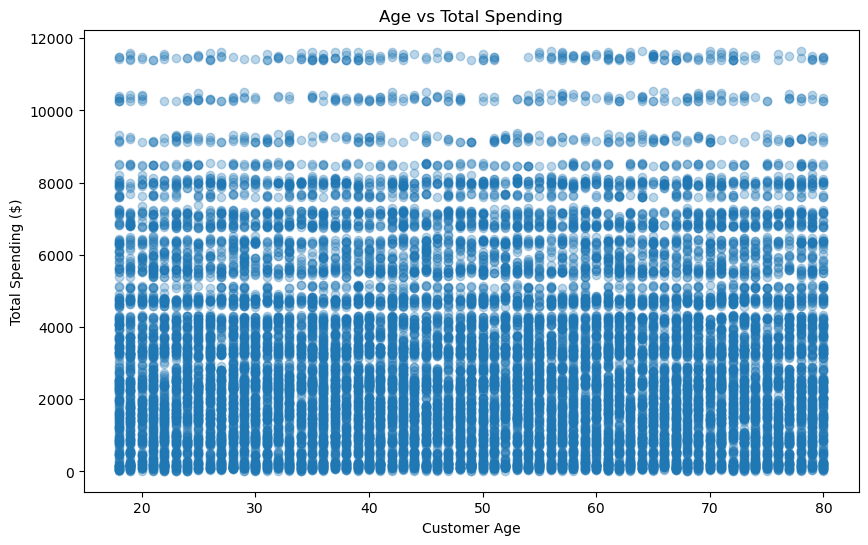

In [17]:
correlation = df.select(
    pl.corr("Age", "Total_Spending")
).item()

print("Correlation:", correlation)

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Age"].to_list(),
    df["Total_Spending"].to_list(),
    alpha=0.3
)

plt.title("Age vs Total Spending")
plt.xlabel("Customer Age")
plt.ylabel("Total Spending ($)")
plt.show()

Based on the analysis, age does not appear to have a significant relationship with total transaction spending. The correlation coefficient is approximately 0.003, which is very close to zero. This suggests that younger and older customers have similar spending patterns overall, and age is not a strong predictor of how much a customer spends per transaction.

# Exercise 3

In this exercise, we will review the design and refactoring concepts from Chapter 8. Answer in your own words (no AI).


### Exercise 3(a) (3 points)

Consider the following function:

```
THRESHOLD = 60000

def flag_high_earners(dataframe):
    dataframe['HighEarner'] = dataframe['Salary'] > THRESHOLD
    return dataframe
```

A colleague changes `THRESHOLD` elsewhere in the module, and the results of `flag_high_earners` silently change. Which statement best describes the design problem and its fix?

A. The function has low cohesion; it should be split into two functions, one for each column it touches.

B. The function is tightly coupled to a hidden module-level value that does not appear in its signature; pass `threshold` as an argument (dependency injection) instead.

C. The function lacks a docstring; adding a description of the `THRESHOLD` value removes the problem.

D. The function is a code smell because it is short; it should be inlined into the calling code.


(B)

### Exercise 3(b) (5 points)

A teammate asks you to restructure a long, untested notebook function so that it is easier to read. They suggest rewriting it from scratch in one large step, and also fixing a few bugs they noticed along the way.

1. Using the definition of refactoring, explain why this plan is risky. (2 points)
2. Describe the steps you would take instead, including what you would do first since there are no tests. (3 points)


1) This plan is risky because refactoring means improving the structure of code without changing how it works. Rewriting everything at once and fixing bugs at the same time makes it difficult to tell what caused a problem if something goes wrong. It could also introduce new errors.

2) Since there are no tests, I would first create tests to check how the original function works. Then, I would make small changes to the code, such as breaking it into smaller functions and improving readability. After each change, I would run the tests to make sure everything still works the same way. Once the refactoring is complete, I would fix the bugs separately and test those fixes as well.